# 05 — Post-merge EDA + analysis spec (Phase 6)

**Input:** `data/interim/analysis_table.csv` (798 films, 1990–2015; Bechdel
rating + dialogue metrics + nominal budget/grosses).

**Purpose:** (1) characterize the merged sample — distributions, missingness,
and how selection sculpted it; (2) check the budget-confounder premise;
(3) LOCK the model specification in writing before any model is run (Phase 7
executes exactly what §6 says, nothing else).

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

INTERIM = Path.cwd().parent / "data" / "interim"
FIGS = Path.cwd().parent / "figures"

df = pd.read_csv(INTERIM / "analysis_table.csv")
spine = pd.read_csv(INTERIM / "spine.csv")
pud = pd.read_csv(INTERIM / "pudding_film.csv")

print(df.shape)
print("\nmissingness:")
print(df.isna().sum()[lambda s: s > 0])

(798, 23)

missingness:
gross_infl_adj_musd     9
distributor            87
mpaa_rating            87
genre                  87
dtype: int64


## 1. Core variables at a glance

In [2]:
core = ["production_budget", "domestic_gross", "worldwide_gross",
        "pct_female_dialogue", "pct_female_characters", "bechdel_rating"]
df[core].describe().round(3)

,production_budget,domestic_gross,worldwide_gross,pct_female_dialogue,pct_female_characters,bechdel_rating
count,7.980000e+02,7.980000e+02,7.980000e+02,798.000,798.000,798.000
mean,5.644791e+07,8.858097e+07,2.027361e+08,0.283,0.310,2.048
std,5.032748e+07,9.872972e+07,2.621748e+08,0.201,0.163,1.032
min,4.500000e+05,3.047100e+04,3.829460e+05,0.000,0.000,0.000
25%,1.650000e+07,2.562756e+07,4.609308e+07,0.129,0.200,1.000
50%,4.000000e+07,5.644647e+07,1.124175e+08,0.233,0.297,2.000
75%,8.000000e+07,1.193511e+08,2.585148e+08,0.387,0.417,3.000
max,3.060000e+08,9.366622e+08,2.923706e+09,0.919,0.889,3.000


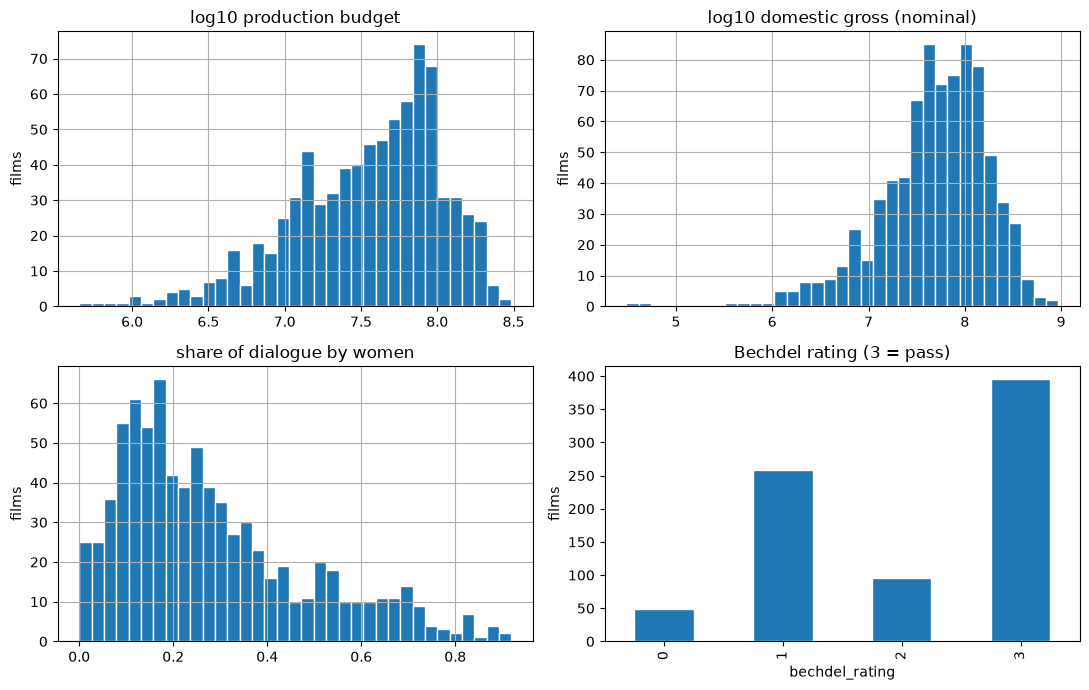

bechdel pass rate: 49.5%


In [3]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
np.log10(df["production_budget"]).hist(bins=35, ax=axes[0, 0], edgecolor="white")
axes[0, 0].set_title("log10 production budget")
np.log10(df.loc[df["domestic_gross"] > 0, "domestic_gross"]).hist(bins=35, ax=axes[0, 1], edgecolor="white")
axes[0, 1].set_title("log10 domestic gross (nominal)")
df["pct_female_dialogue"].hist(bins=35, ax=axes[1, 0], edgecolor="white")
axes[1, 0].set_title("share of dialogue by women")
df["bechdel_rating"].value_counts().sort_index().plot.bar(ax=axes[1, 1], edgecolor="white")
axes[1, 1].set_title("Bechdel rating (3 = pass)")
for ax in axes.flat:
    ax.set_ylabel("films")
fig.tight_layout()
fig.savefig(FIGS / "postmerge_core_distributions.png", dpi=150)
plt.show()
print(f"bechdel pass rate: {df['bechdel_pass'].mean():.1%}")

## 1b. Required EDA statistics

Checklist items the `describe()` call above does not cover, labeled to the
project guidelines so each is easy to locate:

- **EDA Task 2(a)** — mean, median, **mode, variance, skewness, kurtosis**
- **EDA Task 3(a)** — **covariance** alongside correlation
- **EDA Task 2(b)(iii)** — **visualize missing data** and decide whether the
  pattern is critical

In [4]:
# EDA Task 2(a) — full set of required descriptive statistics.
# `mode()` returns a DataFrame (a column can have several tied modes); .iloc[0]
# takes the lowest, which is pandas' documented ordering.
moments = pd.DataFrame({
    "mean": df[core].mean(),
    "median": df[core].median(),
    "mode": df[core].mode().iloc[0],
    "variance": df[core].var(),
    "skewness": df[core].skew(),
    "kurtosis": df[core].kurt(),  # Fisher: 0 = normal, >0 = heavy-tailed
})
print("EDA Task 2(a) — descriptive statistics for the key variables\n")
print(moments.round(3).to_string())

# How often does the reported mode actually repeat? This decides whether the
# mode is a real summary or an artifact of continuous data. Count the value
# `mode()` returned, not `value_counts().index[0]` — when every value occurs
# once those two disagree, since value_counts breaks the tie arbitrarily.
print("\nfrequency of the modal value reported above (is the mode meaningful?):")
for c in core:
    modal = moments.loc[c, "mode"]
    n = int((df[c] == modal).sum())
    print(f"  {c:24s} mode {modal:>13,.4g} occurs {n:3d}x of {len(df)}")

EDA Task 2(a) — descriptive statistics for the key variables

                               mean        median          mode      variance  skewness  kurtosis
production_budget      5.644791e+07  4.000000e+07  3.500000e+07  2.532855e+15     1.407     2.176
domestic_gross         8.858097e+07  5.644647e+07  3.047100e+04  9.747558e+15     2.841    13.403
worldwide_gross        2.027361e+08  1.124175e+08  3.829460e+05  6.873565e+16     3.663    23.402
pct_female_dialogue    2.830000e-01  2.330000e-01  0.000000e+00  4.000000e-02     0.960     0.250
pct_female_characters  3.100000e-01  2.970000e-01  3.330000e-01  2.700000e-02     0.540     0.079
bechdel_rating         2.048000e+00  2.000000e+00  3.000000e+00  1.064000e+00    -0.432    -1.339

frequency of the modal value reported above (is the mode meaningful?):
  production_budget        mode       3.5e+07 occurs  30x of 798
  domestic_gross           mode     3.047e+04 occurs   1x of 798
  worldwide_gross          mode     3.829e+05 occu

In [5]:
# EDA Task 3(a) — covariance and Pearson correlation on the same variables.
print("Covariance matrix (raw units — dollar variables are in dollars^2):\n")
print(df[core].cov().to_string(float_format=lambda v: f"{v:,.3g}"))

print("\n\nPearson correlation matrix (covariance rescaled to [-1, 1]):\n")
print(df[core].corr().round(3).to_string())

Covariance matrix (raw units — dollar variables are in dollars^2):

                       production_budget  domestic_gross  worldwide_gross  pct_female_dialogue  pct_female_characters  bechdel_rating
production_budget               2.53e+15        3.24e+15         9.17e+15            -2.22e+06              -2.28e+06       -6.15e+06
domestic_gross                  3.24e+15        9.75e+15         2.46e+16            -2.49e+06              -2.81e+06        2.04e+06
worldwide_gross                 9.17e+15        2.46e+16         6.87e+16            -6.22e+06              -7.66e+06        5.27e+06
pct_female_dialogue            -2.22e+06       -2.49e+06        -6.22e+06               0.0403                 0.0248           0.113
pct_female_characters          -2.28e+06       -2.81e+06        -7.66e+06               0.0248                 0.0265          0.0825
bechdel_rating                 -6.15e+06        2.04e+06         5.27e+06                0.113                 0.0825           

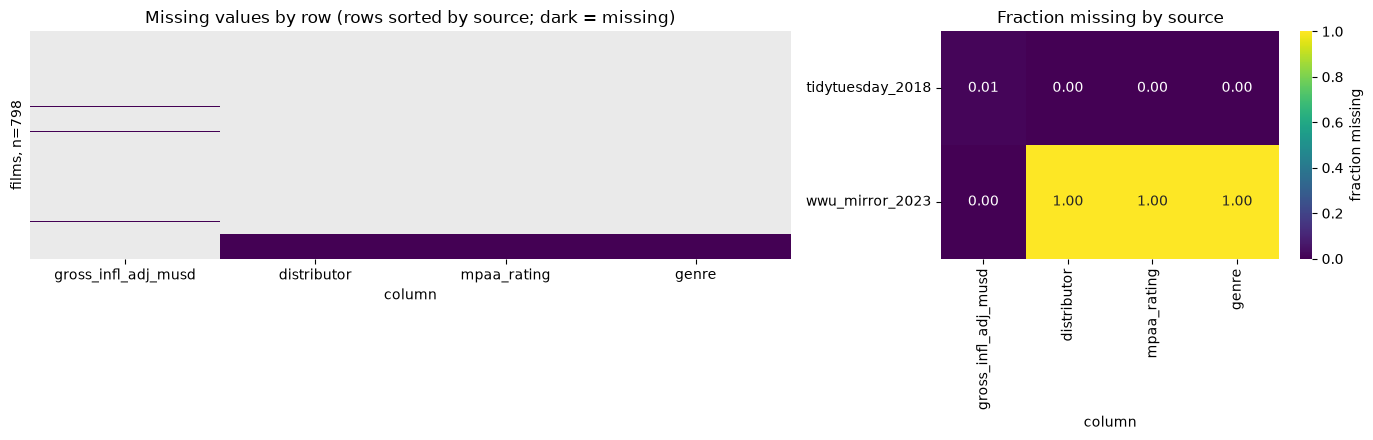

missing counts:
gross_infl_adj_musd     9
distributor            87
mpaa_rating            87
genre                  87

rows missing all three metadata columns: 87  |  missing at least one: 87


In [6]:
# EDA Task 2(b)(iii) — visualize missingness to see whether it is random.
# Rows are sorted by `source` so any source-driven block structure is visible.
import seaborn as sns

miss_cols = df.columns[df.isna().any()].tolist()
ordered = df.sort_values("source")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5),
                         gridspec_kw={"width_ratios": [1.8, 1]})
sns.heatmap(ordered[miss_cols].isna(), cbar=False, yticklabels=False,
            cmap=["#eaeaea", "#440154"], ax=axes[0])
axes[0].set_title("Missing values by row (rows sorted by source; dark = missing)")
axes[0].set_xlabel("column")
axes[0].set_ylabel(f"films, n={len(df)}")

by_source = df.groupby("source")[miss_cols].apply(lambda g: g.isna().mean())
sns.heatmap(by_source, annot=True, fmt=".2f", cmap="viridis",
            vmin=0, vmax=1, ax=axes[1], cbar_kws={"label": "fraction missing"})
axes[1].set_title("Fraction missing by source")
axes[1].set_xlabel("column")
axes[1].set_ylabel("")
axes[1].set_yticklabels(axes[1].get_yticklabels(), rotation=0)
fig.tight_layout()
fig.savefig(FIGS / "postmerge_missingness.png", dpi=150)
plt.show()

print("missing counts:")
print(df[miss_cols].isna().sum().to_string())
m3 = df[["distributor", "mpaa_rating", "genre"]].isna()
print(f"\nrows missing all three metadata columns: {m3.all(axis=1).sum()}"
      f"  |  missing at least one: {m3.any(axis=1).sum()}")

> **My note:** Three things worth reading off these outputs.
>
> **The mode is close to useless on the money columns, and the frequency check
> shows why.** `domestic_gross` and `worldwide_gross` are continuous, so almost
> every value is unique and the "mode" pandas reports occurs exactly once — it
> is just the smallest observation, not a typical value. `production_budget` is
> the exception among the dollar columns: its mode of \$35M occurs 30 times,
> because studios set budgets at round numbers. The mode is genuinely
> informative only for `bechdel_rating`, where 3 occurs 395 times, and
> marginally for `pct_female_characters`, whose modal 0.333 is an artifact of
> films with small named-character counts landing on exactly one third.
>
> **Skewness and kurtosis confirm the log transform used later is required, not
> stylistic.** `worldwide_gross` has skewness 3.66 and kurtosis 23.4;
> `domestic_gross` is 2.84 and 13.4. For reference, a normal distribution sits
> at 0 for both. Those are severe right tails driven by a handful of
> blockbusters, which is exactly the condition under which a linear-scale model
> would let a few films dominate the fit. `bechdel_rating` is the mirror image
> — skewness −0.43 and kurtosis −1.34, a flat, slightly left-leaning
> distribution, which is expected for a bounded 0–3 ordinal.
>
> **The missingness is fully structural, so it is not a threat to the
> analysis.** All 87 films missing `distributor`, `mpaa_rating`, and `genre`
> are missing all three at once, and the right-hand panel shows they are
> exactly the `wwu_mirror_2023` rows — 100% missing from that source, 0% from
> `tidytuesday_2018`. That is a property of the mirror, whose pages only
> carried rank, date, title, budget, and the two grosses; it is not films
> declining to report a genre. The practical consequence is that the genre
> robustness check runs on 711 films rather than 798, which the analysis spec
> already anticipated. The 9 missing `gross_infl_adj_musd` values are
> unrelated and come from Pudding's own gaps.

## 2. The selection funnel — who survives each merge

Every stage keeps bigger films. This table IS the range-restriction
limitation, quantified end to end.

In [7]:
pud_w = pud[pud["year"].between(1990, 2015)]
stages = {
    "1. Pudding window (dialogue data exists)": pud_w.assign(pfd=pud_w["pct_female_dialogue"]),
    "2. + Bechdel rated (spine)": spine.assign(pfd=spine["pct_female_dialogue"]),
    "3. + budget matched (analysis)": df.assign(pfd=df["pct_female_dialogue"]),
}
funnel = pd.DataFrame({
    name: {"films": len(d),
           "mean infl-adj gross ($M)": d["gross_infl_adj_musd"].mean(),
           "median infl-adj gross ($M)": d["gross_infl_adj_musd"].median(),
           "mean % female dialogue": 100 * d["pfd"].mean()}
    for name, d in stages.items()
}).T.round(1)
funnel["films"] = funnel["films"].astype(int)
funnel

,films,mean infl-adj gross ($M),median infl-adj gross ($M),mean % female dialogue
1. Pudding window (dialogue data exists),1587,92.9,50.0,29.0
2. + Bechdel rated (spine),1189,105.9,62.0,30.0
3. + budget matched (analysis),798,124.9,80.0,28.3


## 3. The confounder check — is budget related to BOTH sides?

The design treats budget as the central control because it plausibly drives
gross AND representation. Verify both leg of that claim in-sample.

budget -> gross:      r = 0.663
budget -> %f dialogue: r = -0.265

mean log10 budget by Bechdel rating:
                count        mean      median
bechdel_rating                               
0                  49  68668227.0  62000000.0
1                 259  63424914.0  55000000.0
2                  95  51092632.0  30000000.0
3                 395  51645147.0  35000000.0


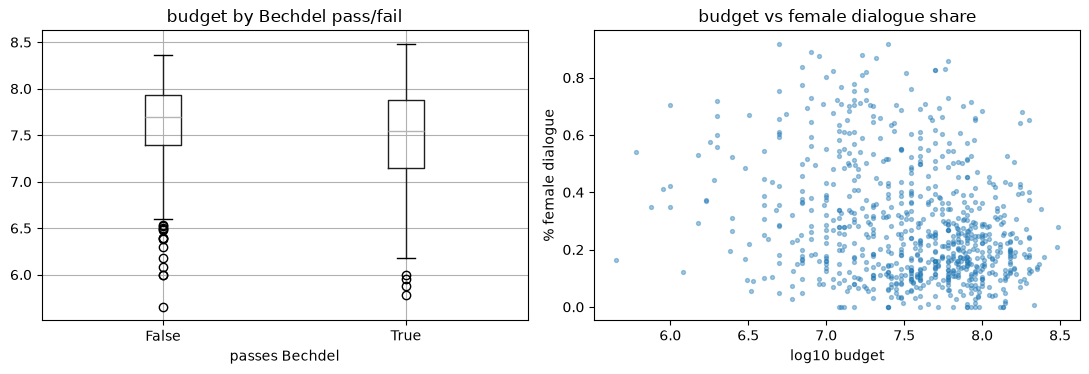

In [8]:
df["log_budget"] = np.log10(df["production_budget"])
df["log_dom"] = np.log10(df["domestic_gross"].where(df["domestic_gross"] > 0))

print("budget -> gross:      r =", df[["log_budget", "log_dom"]].corr().iloc[0, 1].round(3))
print("budget -> %f dialogue: r =", df[["log_budget", "pct_female_dialogue"]].corr().iloc[0, 1].round(3))
print("\nmean log10 budget by Bechdel rating:")
print(df.groupby("bechdel_rating")["production_budget"].agg(["count", "mean", "median"]).round(0))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
df.boxplot(column="log_budget", by="bechdel_pass", ax=axes[0])
axes[0].set_title("budget by Bechdel pass/fail"); axes[0].set_xlabel("passes Bechdel")
axes[1].scatter(df["log_budget"], df["pct_female_dialogue"], s=8, alpha=0.4)
axes[1].set_xlabel("log10 budget"); axes[1].set_ylabel("% female dialogue")
axes[1].set_title("budget vs female dialogue share")
plt.suptitle("")
fig.tight_layout()
fig.savefig(FIGS / "postmerge_budget_confounder.png", dpi=150)
plt.show()

## 4. Raw outcome preview (EDA only — inference happens in Phase 7)

In [9]:
print("mean log10 domestic gross by Bechdel pass (RAW, unadjusted):")
print(df.groupby("bechdel_pass")["log_dom"].agg(["count", "mean"]).round(3))

# same comparison within budget terciles — a hand-rolled preview of 'controlling for budget'
df["budget_tercile"] = pd.qcut(df["production_budget"], 3, labels=["low", "mid", "high"])
prev = df.groupby(["budget_tercile", "bechdel_pass"], observed=True)["log_dom"].mean().unstack().round(3)
prev["gap (pass - fail)"] = (prev[True] - prev[False]).round(3)
print("\nwithin budget terciles:")
print(prev)

mean log10 domestic gross by Bechdel pass (RAW, unadjusted):
              count   mean
bechdel_pass              
False           403  7.690
True            395  7.677

within budget terciles:
bechdel_pass    False   True  gap (pass - fail)
budget_tercile                                 
low             7.162  7.330              0.168
mid             7.733  7.733              0.000
high            8.029  8.145              0.116


## 5. Year coverage sanity

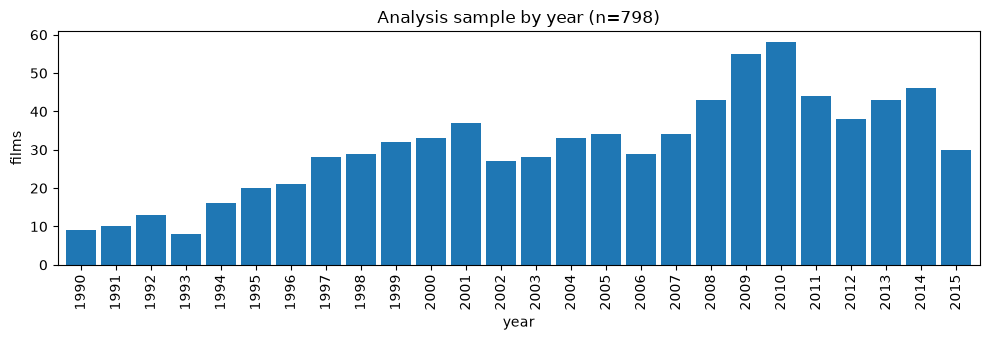

In [10]:
fig, ax = plt.subplots(figsize=(10, 3.5))
df.groupby("year").size().plot.bar(ax=ax, width=0.85)
ax.set_ylabel("films"); ax.set_title("Analysis sample by year (n=798)")
ax.tick_params(axis="x", labelrotation=90)
fig.tight_layout()
fig.savefig(FIGS / "postmerge_year_coverage.png", dpi=150)
plt.show()

## 6. 🔒 ANALYSIS SPEC — locked before modeling

*Written 2026-07-05, before any model was run. Phase 7 (`06_analysis.ipynb`)
implements exactly this; any deviation gets documented as a deviation.*

**Research question (associational, not causal):** among commercially released
US films 1990–2015 with dialogue data, how do Bechdel passage and female
dialogue share relate to box-office outcomes, holding budget and era fixed?

**Sample:** the 798-film analysis table. No further row filters. 
(`domestic_gross` has no zeros; if any variable is missing for a model, the
model's N is reported.)

**Outcome:** `log10(domestic_gross)` — nominal, from The Numbers. Nominal is
acceptable because every model controls for year; the year term absorbs
price-level drift. (Pudding's inflation-adjusted gross is NOT mixed in;
it appears only in a robustness check as an alternative outcome.)

**Primary predictor (M1):** `bechdel_pass` (rating == 3, binary).
**Secondary predictor (M2):** `pct_female_dialogue` (continuous, per 10pp).

**Controls (both models):** `log10(production_budget)` (the central control) +
`year` (continuous linear; simple and sufficient for a 26-year window).

**Estimator:** OLS with heteroskedasticity-robust (HC3) standard errors,
via `statsmodels` (to be added to requirements.txt at Phase 7 start).
Report coefficients, 95% CIs, and R²; interpret the Bechdel coefficient as
the % difference in gross associated with passing, at fixed budget and year.

**Pre-declared robustness checks (no fishing beyond these):**
1. Outcome swap: `log10(worldwide_gross)`
2. Outcome swap: Pudding inflation-adjusted domestic gross
3. Predictor as ordinal: rating 0/1/2/3 category dummies (0 = reference)
4. Add genre dummies (only the 691 films with genre; report both Ns)

**What we will NOT do:** interpret coefficients causally; add post-hoc
predictors; select models on p-values.

**Known limitations carried into interpretation:** triple selection funnel
(§2 — sample skews large-budget and less female-forward at each stage);
binary gender coding; 2021 Bechdel mirror (no dubious flag); 2015 cutoff.

## Appendix — week 8 discussion figure: bin edges vs. color scale

Not part of the analysis spec (§6 above remains the locked plan). Built for a
DSC 530 discussion post asking whether a log **color** scale was fixing the
right problem on a year-by-gross count heatmap, or whether the **bin edges**
were the real culprit.

Three panels isolate the two choices instead of changing both at once:
matrix **A** uses 12 equal-width dollar bins, matrix **B** uses 12 log-spaced
edges over the same range. Panels 1 and 2 hold the binning fixed and vary the
color scale; panels 1 and 3 hold the color scale fixed and vary the binning.

films binned — A: 798, B: 798 (of 798); none dropped


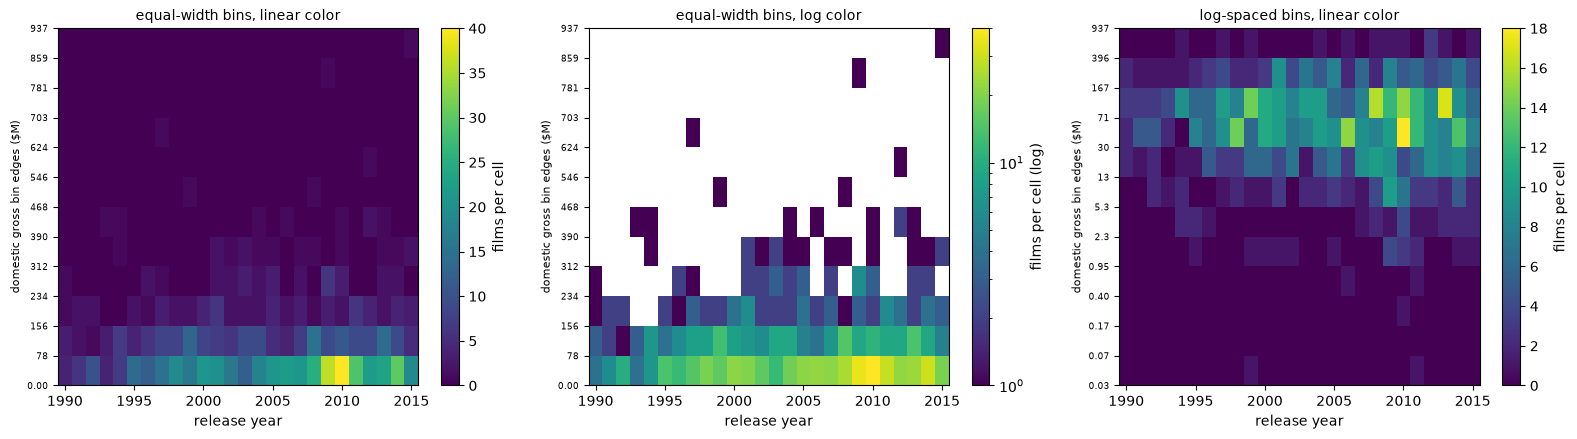


A equal-width: films per bin (low -> high) = [482, 191, 65, 31, 15, 8, 2, 1, 1, 0, 1, 1]
               zero cells = 198/312, max cell = 40

B log-spaced : films per bin (low -> high) = [2, 0, 1, 2, 17, 21, 59, 127, 222, 230, 104, 13]
               zero cells = 150/312, max cell = 18


In [11]:
from matplotlib.colors import LogNorm

g = df["domestic_gross"]

# --- matrix A: 12 equal-width dollar bins (the original choice) ---
A = df.groupby([pd.cut(g, bins=12), "year"], observed=False).size().unstack(fill_value=0)

# --- matrix B: 12 log-spaced edges over the same range ---
# np.log10 -> 10** round-trips the endpoints through float, landing the first
# edge a hair ABOVE the true minimum; pd.cut would then drop the cheapest film
# (The Boondock Saints, 1999, $30,471) to NaN even with include_lowest=True.
# Clamp both endpoints outward so every film is binned, none silently dropped.
lo, hi = g[g > 0].min(), g.max()
edges = np.logspace(np.log10(lo), np.log10(hi), 13)
edges[0], edges[-1] = np.nextafter(lo, 0.0), np.nextafter(hi, np.inf)
B_bins = pd.cut(g, bins=edges, include_lowest=True)
assert B_bins.isna().sum() == 0, "films fell outside the log-spaced edges"
B = df.groupby([B_bins, "year"], observed=False).size().unstack(fill_value=0)
print(f"films binned — A: {A.sum().sum()}, B: {B.sum().sum()} (of {len(df)}); none dropped")


def edge_labels(idx):
    """Row-boundary labels in $M — panel 3's rows are unequal in dollar width."""
    vals = [iv.left for iv in idx] + [idx[-1].right]
    out = []
    for v in vals:
        v = max(v, 0) / 1e6
        out.append(f"{v:,.2f}" if v < 1 else (f"{v:,.1f}" if v < 10 else f"{v:,.0f}"))
    return out


fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
panels = [
    (axes[0], A, None, "equal-width bins, linear color", "films per cell"),
    (axes[1], A, LogNorm(vmin=1, vmax=A.to_numpy().max()), "equal-width bins, log color", "films per cell (log)"),
    (axes[2], B, None, "log-spaced bins, linear color", "films per cell"),
]
for ax, M, norm, title, cbar_label in panels:
    im = ax.imshow(M.to_numpy(), aspect="auto", origin="lower", cmap="viridis", norm=norm)
    ax.set_title(title, fontsize=10)
    ax.set_xlabel("release year")
    ax.set_xticks(range(0, M.shape[1], 5))
    ax.set_xticklabels(M.columns[::5])
    ax.set_yticks(np.arange(-0.5, 12.5, 1))
    ax.set_yticklabels(edge_labels(M.index), fontsize=6.5)
    ax.set_ylabel("domestic gross bin edges ($M)", fontsize=8)
    fig.colorbar(im, ax=ax, label=cbar_label)
fig.tight_layout()
fig.savefig(FIGS / "week8_bins_vs_color.png", dpi=150)
plt.show()

for name, M in [("A equal-width", A), ("B log-spaced ", B)]:
    a = M.to_numpy()
    print(f"\n{name}: films per bin (low -> high) = {list(M.sum(axis=1))}")
    print(f"{' ' * len(name)}  zero cells = {(a == 0).sum()}/{a.size}, max cell = {a.max()}")

> **My note:** Equal-width dollar bins pile films into the first bin because
> `pd.cut` divides the *range*, not the data. Domestic gross here runs from
> \$30K to \$937M, so 12 equal slices are ~\$78M wide — but the median film
> earns \$56M, so bin 1 alone swallows 482 of 798 films (60%) while the top
> six bins share 6 films between them. The bin edges are evenly spaced in a
> unit nobody is evenly distributed in. That produces a matrix that is 63.5%
> zeros with a single 40-film cell, and *that* extreme dynamic range is what
> made a log color scale look necessary.
>
> Log-spaced edges (`np.logspace`) divide the range in *orders of magnitude*
> instead, so each row spans a constant multiplicative step (~2.4×) rather
> than a constant \$78M. Because gross is roughly log-normal, films spread out:
> the top six bins go from 6 films to 755, and the max cell drops 40 → 18.
> Two things worth flagging. First, the emptiness **moves rather than
> disappears** — the four bins under \$1M hold 5 films total, so panel 3 is
> dead at the *bottom* where panels 1–2 were dead at the *top*, and zeros only
> fall 198 → 150. A handful of flops stretches the log range down just as a
> handful of blockbusters stretched the linear range up. Second, `np.logspace`
> round-trips its endpoints through `log10`/`10**`, landing the first edge
> just above the true minimum; `pd.cut` then drops that film to `NaN` **even
> with `include_lowest=True`**, which is why the cell clamps both endpoints
> outward and asserts the count.
>
> Does the color scale still matter once the binning is fixed? Much less. On
> matrix A the median non-zero cell is 3 films, sitting at 3/40 = 0.08 of a
> linear ramp — nearly black. On matrix B it is 4 films at 4/18 = 0.22, which
> is a legible blue. The log color scale was compensating for a binning
> choice, and once the edges match the distribution's shape, a plain linear
> ramp reads fine. `LogNorm` also carries a cost the linear ramp does not:
> `log(0)` is undefined, so every zero cell is masked to the colormap's "bad"
> color — transparent by default — and renders as white. In panel 2 that is
> 198 cells showing as blank holes indistinguishable from "no data," when the
> data says "zero films observed." Worse, `vmin=1` puts every count-1 cell at
> colormap position 0.000, the darkest purple — so across the sparse upper
> rows the *only* visible change from panel 1 to panel 2 is dark purple
> becoming white. `SymLogNorm(linthresh=1)` avoids both problems: it stays
> linear inside ±1 and goes logarithmic beyond, so 0 is a valid value that
> gets the true bottom of the ramp and 1 is visibly distinct from it.